# 미니프로젝트 Day 1 · 공유자전거 대여 수요 예측 (회귀)

**사용법**: 위에서 아래로 셀을 **순서대로** 실행합니다 (`Shift + Enter`). 앞 셀에서 만든 변수를 뒤 셀이 사용하므로 건너뛰면 에러가 납니다.
마지막에 메뉴의 **Restart → Run All**로 처음부터 에러 없이 끝나는지 확인하세요.

**전체 흐름**: 데이터 탐색(CP-01) → 분할·누수·상관관계(CP-02) → 특성공학·전처리(CP-03) → Dummy·선형회귀(CP-04) → 트리(CP-05) → 랜덤포레스트·비교(CP-06) → 오류 분석(CP-07) → 최종 모델·저장·예측(CP-08)

`✏️ 내 메모` 셀은 결과를 본 뒤 **본인 말로** 채우는 칸입니다. 나중에 `docs/adr.md`와 분석 보고서의 재료가 됩니다.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("라이브러리 불러오기 완료")

라이브러리 불러오기 완료


---
# ① CP-01 · 데이터 탐색 및 시각화

**목표**: `hour.csv`의 구조와 품질을 파악하고, 시간대별 대여 패턴을 그래프로 설명할 수 있게 만듭니다.

### 1단계. 데이터 불러오기
`pd.read_csv()`로 CSV를 표(DataFrame)로 읽습니다. 노트북이 `code/` 폴더에 있으므로 `../data/hour.csv`는 "한 단계 위로 올라가서 `data` 폴더의 `hour.csv`"라는 뜻입니다.

In [2]:
df = pd.read_csv("../data/hour.csv")

print("행·열 개수:", df.shape)          # 기대값: (17379, 17)
print()
print("컬럼명과 자료형")
df.info()

행·열 개수: (17379, 17)

컬럼명과 자료형
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [3]:
print("처음 5개 행")
display(df.head())

print("주요 컬럼의 기초 통계량")
display(df[["temp", "atemp", "hum", "windspeed", "cnt"]].describe())

처음 5개 행


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


주요 컬럼의 기초 통계량


,temp,atemp,hum,windspeed,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,0.496987,0.475775,0.627229,0.190098,189.463088
std,0.192556,0.171850,0.192930,0.122340,181.387599
min,0.020000,0.000000,0.000000,0.000000,1.000000
25%,0.340000,0.333300,0.480000,0.104500,40.000000
50%,0.500000,0.484800,0.630000,0.194000,142.000000
75%,0.660000,0.621200,0.780000,0.253700,281.000000
max,1.000000,1.000000,1.000000,0.850700,977.000000


**읽는 법**
- `cnt`: 우리가 예측할 값(시간당 총 대여량). `casual`(비회원) + `registered`(회원) = `cnt`입니다.
- `temp`, `atemp`, `hum`, `windspeed`는 0~1 사이로 **정규화된 값**입니다 (실제 °C가 아닙니다).
- `hr`: 시간대(0~23), `workingday`: 근무일 여부(1/0), `weathersit`: 날씨 상태(1 맑음 ~ 4 악천후).

### 2단계. 데이터 품질 확인
결측값(빈 칸), 중복 행, 예측 대상 `cnt`의 분포를 봅니다.

결측값 총 개수: 0
중복 행 개수  : 0


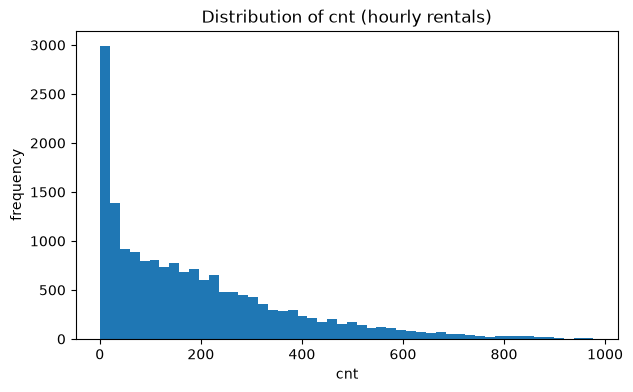

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

In [4]:
print("결측값 총 개수:", df.isnull().sum().sum())
print("중복 행 개수  :", df.duplicated().sum())

plt.figure(figsize=(7, 4))
plt.hist(df["cnt"], bins=50)
plt.title("Distribution of cnt (hourly rentals)")
plt.xlabel("cnt")
plt.ylabel("frequency")
plt.show()

display(df["cnt"].describe())

**읽는 법**: 막대가 왼쪽(작은 값)에 몰리고 오른쪽으로 길게 늘어진 모양이면, 대여량이 적은 시간대가 많고 아주 많은 시간대는 드물다는 뜻입니다.

### 3단계. 시간대별 평균 대여량
`groupby('hr')`로 시간대별 평균 `cnt`를 구하고 그래프로 그립니다.

,mean_cnt
hr,
0,53.9
1,33.4
2,22.9
3,11.7
4,6.4
5,19.9
6,76.0
7,212.1
8,359.0


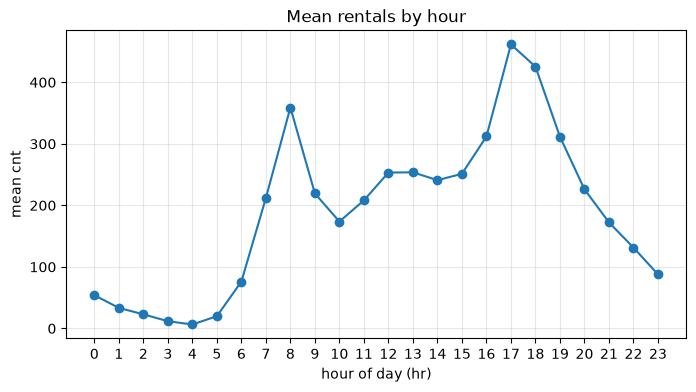

In [5]:
hourly = df.groupby("hr")["cnt"].mean()
display(hourly.round(1).to_frame("mean_cnt"))

plt.figure(figsize=(8, 4))
plt.plot(hourly.index, hourly.values, marker="o")
plt.xticks(range(0, 24))
plt.xlabel("hour of day (hr)")
plt.ylabel("mean cnt")
plt.title("Mean rentals by hour")
plt.grid(alpha=0.3)
plt.show()

### ✏️ 내 메모 (CP-01) — 그래프를 보고 직접 채우세요
- 대여량이 가장 많은 시간대는 몇 시이고, 그 이유는 무엇일까요?
- 대여량이 가장 적은 시간대는 언제인가요?
- 출퇴근 시간(오전 7~9시, 오후 17~19시)에 어떤 모양이 나타났나요?
- 결측값/중복 행 결과와 `cnt` 분포의 특징은?

(여기에 적기)

**선택 심화 (시간 있을 때)**: 평일과 주말의 시간대별 대여량을 비교해 봅니다. 평일은 출퇴근 때 봉우리 2개, 주말은 낮에 봉우리 1개가 나오는지 확인해 보세요.

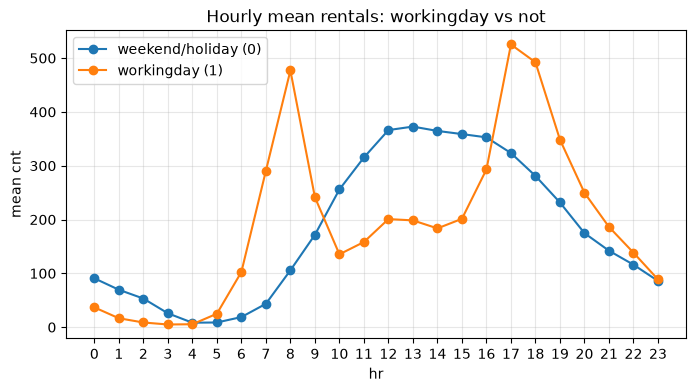

In [6]:
by_work = df.groupby(["workingday", "hr"])["cnt"].mean().unstack(0)
by_work.columns = ["weekend/holiday (0)", "workingday (1)"]
by_work.plot(figsize=(8, 4), marker="o")
plt.xticks(range(0, 24))
plt.ylabel("mean cnt")
plt.title("Hourly mean rentals: workingday vs not")
plt.grid(alpha=0.3)
plt.show()

---
# ② CP-02 · 데이터 분할 · 누수 확인 · 상관관계 · 입력 특성 선택

### 1단계. 날짜 순서로 분할 (Train 70% / Validation 15% / Test 15%)

이 데이터는 **시간 순서가 있는 기록**입니다. 무작위로 섞어서 나누면, 미래 기록으로 학습하고 과거를 맞히는 상황이 생겨 성능이 실제보다 좋아 보입니다. 그래서 **앞선 기간은 Train, 중간은 Validation, 마지막은 Test**로 나눕니다.

또 같은 날짜의 24개 행이 서로 다른 집합에 흩어지면 안 되므로, **행 번호가 아니라 날짜를 기준으로** 자릅니다.

In [7]:
df["dteday"] = pd.to_datetime(df["dteday"])
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)

# 날짜 목록(중복 제거 후 정렬) 기준으로 70%, 85% 지점의 날짜를 경계로 사용
dates = df["dteday"].drop_duplicates().sort_values().reset_index(drop=True)
split_1 = dates.iloc[int(len(dates) * 0.70)]   # 이 날짜부터 Validation
split_2 = dates.iloc[int(len(dates) * 0.85)]   # 이 날짜부터 Test

train = df[df["dteday"] < split_1].copy()
valid = df[(df["dteday"] >= split_1) & (df["dteday"] < split_2)].copy()
test  = df[df["dteday"] >= split_2].copy()

for name, d in [("Train", train), ("Validation", valid), ("Test", test)]:
    print(f"{name:10s} 행 {len(d):6d} ({len(d)/len(df):.1%})  날짜 {d['dteday'].min().date()} ~ {d['dteday'].max().date()}")

# 같은 날짜가 두 집합에 걸쳐 있지 않은지 확인
overlap = (set(train["dteday"]) & set(valid["dteday"])) | (set(valid["dteday"]) & set(test["dteday"]))
print("집합 간 겹치는 날짜 수:", len(overlap), "(0이어야 정상)")

Train      행  12139 (69.8%)  날짜 2011-01-01 ~ 2012-05-25
Validation 행   2640 (15.2%)  날짜 2012-05-26 ~ 2012-09-12
Test       행   2600 (15.0%)  날짜 2012-09-13 ~ 2012-12-31
집합 간 겹치는 날짜 수: 0 (0이어야 정상)


### 2단계. 데이터 누수 확인

`cnt`, `casual`, `registered`의 관계를 계산합니다. 만약 `casual + registered = cnt`라면, `casual`과 `registered`는 **정답을 거의 그대로 담은 값**입니다. 예측하려는 그 시간의 대여가 끝나야 알 수 있는 값이라서, 실제 예측 시점에는 쓸 수 없습니다. 이런 값을 입력에 넣으면 **데이터 누수**가 생깁니다.

In [8]:
diff = (df["casual"] + df["registered"] - df["cnt"]).abs().max()
print("casual + registered 와 cnt 의 최대 차이:", diff, "(0이면 완전히 같다는 뜻)")
print()
display(df[["casual", "registered", "cnt"]].corr().round(3))

casual + registered 와 cnt 의 최대 차이: 0 (0이면 완전히 같다는 뜻)



,casual,registered,cnt
casual,1.000,0.507,0.695
registered,0.507,1.000,0.972
cnt,0.695,0.972,1.000


### 3단계. 상관관계 분석 (Train 데이터만 사용)

상관관계를 **Train에서만** 계산하는 이유: Validation·Test 정보를 보고 특성을 고르면 그 집합이 이미 선택에 쓰인 셈이 되기 때문입니다.

> 상관계수는 **직선 관계**만 보여주며 인과관계가 아닙니다. 값이 낮아도 비선형 관계가 있을 수 있으므로 상관계수만 보고 특성을 제거하지 않습니다.

In [9]:
corr_cols = ["temp", "atemp", "hum", "windspeed", "cnt"]
corr = train[corr_cols].corr().round(3)
display(corr)

,temp,atemp,hum,windspeed,cnt
temp,1.000,0.992,-0.016,-0.015,0.398
atemp,0.992,1.000,-0.000,-0.058,0.398
hum,-0.016,-0.000,1.000,-0.297,-0.301
windspeed,-0.015,-0.058,-0.297,1.000,0.094
cnt,0.398,0.398,-0.301,0.094,1.000


### ✏️ 내 메모 (CP-02) — 표를 보고 직접 채우세요
- `cnt`와 **양(+)**의 상관을 보인 특성은? (예: 기온)
- `cnt`와 **음(−)**의 상관을 보인 특성은? (예: 습도)
- 서로 상관이 매우 높은 입력 특성 쌍은? (`temp`와 `atemp`) 이 경우 어떻게 생각하나요?
- `casual`, `registered`를 입력에서 뺀 이유는?

(여기에 적기)

### 4단계. 입력 특성 선택, X/y 분리

- **제외**: `casual`, `registered`(누수), `cnt`(정답), `instant`(단순 행 번호), `dteday`(날짜 문자열. 날짜 정보는 `yr`, `mnth`, `weekday`, `hr` 등으로 이미 들어 있음)
- **사용**: 시간·계절·요일·근무일·날씨·기온·습도·풍속

이 단계에서는 기본 특성으로 `X_train`~`y_test` 6개 변수를 만들고, ③교시에서 `is_commute_hour`를 추가한 뒤 다시 만듭니다.

In [10]:
BASE_FEATURES = ["season", "yr", "mnth", "hr", "weekday", "holiday", "workingday",
                 "weathersit", "temp", "atemp", "hum", "windspeed"]
TARGET = "cnt"

X_train, y_train = train[BASE_FEATURES], train[TARGET]
X_valid, y_valid = valid[BASE_FEATURES], valid[TARGET]
X_test,  y_test  = test[BASE_FEATURES],  test[TARGET]

print("X_train", X_train.shape, "| y_train", y_train.shape)
print("X_valid", X_valid.shape, "| y_valid", y_valid.shape)
print("X_test ", X_test.shape,  "| y_test ", y_test.shape)

X_train (12139, 12) | y_train (12139,)
X_valid (2640, 12) | y_valid (2640,)
X_test  (2600, 12) | y_test  (2600,)


---
# ③ CP-03 · 특성공학 및 데이터 전처리

### 1단계. 새로운 특성 `is_commute_hour` 만들기

`hr`(시간대)과 `workingday`(근무일)를 **조합**해서, "근무일이면서 출퇴근 시간대(7~9시, 17~19시)"이면 1, 아니면 0인 특성을 만듭니다.

왜 만들까요? `hr`과 `workingday`가 따로 있어도, 선형회귀 같은 모델은 "근무일의 출퇴근 때만 대여가 급증한다"는 **조합 효과**를 스스로 만들지 못합니다. 조합 특성을 직접 주면 그 패턴을 쉽게 학습합니다.

함수로 만들어 두는 이유: ⑧교시 `predict_demand()`에서도 **똑같은 방식**으로 이 특성을 만들어야 하기 때문입니다.

In [11]:
def add_commute_feature(d):
    """근무일이면서 7~9시 또는 17~19시이면 1, 아니면 0인 is_commute_hour 컬럼을 추가한다."""
    d = d.copy()
    is_commute_time = d["hr"].between(7, 9) | d["hr"].between(17, 19)
    d["is_commute_hour"] = ((d["workingday"] == 1) & is_commute_time).astype(int)
    return d

# Train / Validation / Test에 똑같이 적용
train = add_commute_feature(train)
valid = add_commute_feature(valid)
test  = add_commute_feature(test)

# 표로 정의한 예시와 일치하는지 확인 (8시·근무일=1, 8시·근무일=0, 14시·근무일=1, 18시·근무일=1)
check = add_commute_feature(pd.DataFrame({"hr": [8, 8, 14, 18], "workingday": [1, 0, 1, 1]}))
display(check)   # is_commute_hour 기대값: 1, 0, 0, 1

,hr,workingday,is_commute_hour
0,8,1,1
1,8,0,0
2,14,1,0
3,18,1,1


### 2단계. 특성 유형 구분

| 유형 | 의미 | 처리 | 컬럼 |
| --- | --- | --- | --- |
| 범주형 | 숫자지만 값이 "종류"를 뜻함 | `OneHotEncoder` | season, yr, mnth, hr, weekday, weathersit |
| 수치형 | 크기에 의미가 있음 | `StandardScaler` | temp, atemp, hum, windspeed |
| 이진 | 0 또는 1 | 그대로 통과 | holiday, workingday, is_commute_hour |

`hr`이 범주형인 이유: 23시가 0시보다 "크다"는 순서 관계가 대여량과 직선으로 맞지 않고, 시간대마다 고유한 패턴이 있기 때문입니다.

In [12]:
CAT_COLS = ["season", "yr", "mnth", "hr", "weekday", "weathersit"]
NUM_COLS = ["temp", "atemp", "hum", "windspeed"]
BIN_COLS = ["holiday", "workingday", "is_commute_hour"]
FEATURES = CAT_COLS + NUM_COLS + BIN_COLS

# 새 특성이 들어간 FEATURES로 X/y를 다시 만든다
X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

print("입력 특성", len(FEATURES), "개:", FEATURES)

입력 특성 13 개: ['season', 'yr', 'mnth', 'hr', 'weekday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'holiday', 'workingday', 'is_commute_hour']


### 3~4단계. 전처리 객체 만들고 검증하기

- `StandardScaler`: 평균 0, 표준편차 1로 맞춥니다.
- `OneHotEncoder`: 범주마다 0/1 열을 만듭니다. `handle_unknown="ignore"`는 Train에 없던 값이 나와도 에러 없이 처리합니다.
- `ColumnTransformer`: 열마다 다른 변환을 묶습니다. `remainder="passthrough"`는 이진 특성을 그대로 통과시킵니다.

**핵심 규칙**: 평균·표준편차 같은 기준은 **Train에서만 `fit`** 하고, Validation·Test에는 **`transform`만** 합니다. 그래야 평가용 데이터의 정보가 전처리에 새어 들어가지 않습니다(데이터 누수 방지).

`make_preprocessor()`를 함수로 만들어 두면 모델마다 **새 전처리 객체**를 만들 수 있습니다.

In [13]:
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), NUM_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
        ],
        remainder="passthrough",   # BIN_COLS(이진 특성)는 그대로 통과
    )

pre = make_preprocessor()
Xt = pre.fit_transform(X_train)   # Train에서만 기준을 학습(fit)하고 변환
Xv = pre.transform(X_valid)       # Validation에는 같은 기준을 적용(transform만)

print("Train 변환 Shape     :", Xt.shape)
print("Validation 변환 Shape:", Xv.shape)
print("열 개수가 같아야 정상:", Xt.shape[1] == Xv.shape[1])

Train 변환 Shape     : (12139, 60)
Validation 변환 Shape: (2640, 60)
열 개수가 같아야 정상: True


**Shape 읽는 법**: `(행 수, 열 수)`입니다. 열 수는 수치형 4 + 범주형이 펼쳐진 열(season 4 + yr 2 + mnth 12 + hr 24 + weekday 7 + weathersit 3~4) + 이진 3개입니다. Train과 Validation의 **열 수가 같으면** 정상입니다.

### ✏️ 내 메모 (CP-03)
- 시간·근무일 정보가 이미 있는데 `is_commute_hour`를 또 만든 이유는? (위 설명을 본인 말로)
- 전처리를 Train에서만 fit한 이유는?

(여기에 적기)

---
# ④ CP-04 · 기준 모델과 선형회귀

### 평가 함수 `evaluate_regression()`
이후 모든 모델에 **같은 함수**를 써서 공정하게 비교합니다.

| 지표 | 의미 |
| --- | --- |
| **MAE** | 평균적으로 몇 대 틀렸는가 (단위: 대) |
| **RMSE** | 큰 오차를 더 크게 반영한 평균 오차 (단위: 대) |
| **R²** | "평균값으로 예측"했을 때보다 얼마나 나아졌는가. 1에 가까울수록 좋고, 0이면 평균 예측과 같고, 음수면 더 나쁨 |

### 모델 만들기
- **DummyRegressor**: 입력 특성을 쓰지 않고 Train 정답의 평균만 답하는 **기준 모델**. 다른 모델이 이보다 좋아야 의미가 있습니다.
- **LinearRegression**: 각 입력에 계수를 곱해 더하는 선형 모델.
- 둘 다 `Pipeline`(전처리 → 모델)으로 묶어 Train에서만 학습합니다.

In [14]:
def evaluate_regression(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
    }

# 이후 실험할 모든 모델을 이름으로 관리
MODEL_FACTORIES = {
    "Dummy":    lambda: DummyRegressor(strategy="mean"),
    "Linear":   lambda: LinearRegression(),
    "Tree_d3":  lambda: DecisionTreeRegressor(max_depth=3,  random_state=42),
    "Tree_d6":  lambda: DecisionTreeRegressor(max_depth=6,  random_state=42),
    "Tree_d12": lambda: DecisionTreeRegressor(max_depth=12, random_state=42),
    "RF_A":     lambda: RandomForestRegressor(n_estimators=50,  max_depth=10, random_state=42, n_jobs=-1),
    "RF_B":     lambda: RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
}

results = {}   # 모델 이름 -> 성능 (같은 모델을 다시 실행해도 중복되지 않게 dict 사용)
fitted = {}    # 모델 이름 -> 학습된 Pipeline

def run_model(name):
    pipe = Pipeline([("pre", make_preprocessor()), ("model", MODEL_FACTORIES[name]())])
    pipe.fit(X_train, y_train)                                   # Train으로만 학습
    tr = evaluate_regression(y_train, pipe.predict(X_train))
    va = evaluate_regression(y_valid, pipe.predict(X_valid))
    results[name] = {**{f"train_{k}": v for k, v in tr.items()},
                     **{f"valid_{k}": v for k, v in va.items()}}
    fitted[name] = pipe

def results_table(names=None):
    t = pd.DataFrame(results).T
    if names is not None:
        t = t.loc[names]
    return t.round(3)

for name in ["Dummy", "Linear"]:
    run_model(name)

display(results_table(["Dummy", "Linear"]))

,train_MAE,train_RMSE,train_R2,valid_MAE,valid_RMSE,valid_R2
Dummy,119.572,152.40,0.000,194.518,254.607,-0.296
Linear,55.333,73.41,0.768,99.965,124.356,0.691


**읽는 법**: 선형회귀의 Validation MAE·RMSE가 Dummy보다 **작고**, R²가 Dummy(0 근처)보다 **크면** 기준 모델보다 나아진 것입니다.

### ✏️ 내 메모 (CP-04)
- 선형회귀가 기준 모델보다 좋아졌나요? 어떤 지표(숫자)로 판단했나요?
- Train과 Validation 성능 차이는 큰가요?

(여기에 적기)

---
# ⑤ CP-05 · Decision Tree와 깊이 실험

`max_depth`는 트리가 조건을 얼마나 깊이 나눌 수 있는지 정하는 값입니다.
- 너무 **얕으면** 패턴을 충분히 못 배웁니다 (과소적합: Train·Validation 오차가 둘 다 큼).
- 너무 **깊으면** 훈련 데이터에만 맞춥니다 (과대적합: Train 오차는 작은데 Validation 오차는 큼).

깊이 3, 6, 12로 실험해 Train/Validation MAE를 비교합니다.

,train_MAE,valid_MAE,gap(valid-train)
max_depth,,,
3,82.785,158.697,75.912
6,62.340,120.425,58.085
12,32.297,104.740,72.443


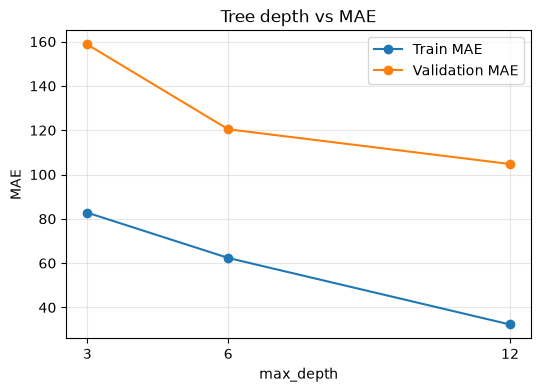

In [15]:
for name in ["Tree_d3", "Tree_d6", "Tree_d12"]:
    run_model(name)

depth_df = results_table(["Tree_d3", "Tree_d6", "Tree_d12"])[["train_MAE", "valid_MAE"]].copy()
depth_df.index = [3, 6, 12]
depth_df.index.name = "max_depth"
depth_df["gap(valid-train)"] = (depth_df["valid_MAE"] - depth_df["train_MAE"]).round(3)
display(depth_df)

plt.figure(figsize=(6, 4))
plt.plot(depth_df.index, depth_df["train_MAE"], marker="o", label="Train MAE")
plt.plot(depth_df.index, depth_df["valid_MAE"], marker="o", label="Validation MAE")
plt.xticks([3, 6, 12])
plt.xlabel("max_depth")
plt.ylabel("MAE")
plt.title("Tree depth vs MAE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**읽는 법**
- 깊이가 늘수록 Train MAE는 계속 줄어드는데 Validation MAE는 줄다가 **다시 커지거나 격차가 벌어지면** 과대적합의 단서입니다.
- 깊이 3에서 두 오차가 모두 크다면 과소적합의 단서입니다.

### ✏️ 내 메모 (CP-05)
- 깊이가 커질 때 Train MAE와 Validation MAE는 각각 어떻게 변했나요?
- 어느 깊이에서 과대적합 가능성이 보이나요? 그래프의 어떤 모습이 근거인가요?

(여기에 적기)

**선택 심화**: `min_samples_leaf`(리프 하나에 최소 몇 개 샘플이 있어야 하는지)를 바꿔 과대적합이 줄어드는지 확인합니다.

In [16]:
for leaf in [1, 5, 20, 50]:
    p = Pipeline([("pre", make_preprocessor()),
                  ("model", DecisionTreeRegressor(max_depth=12, min_samples_leaf=leaf, random_state=42))])
    p.fit(X_train, y_train)
    tr = mean_absolute_error(y_train, p.predict(X_train))
    va = mean_absolute_error(y_valid, p.predict(X_valid))
    print(f"min_samples_leaf={leaf:3d}  Train MAE={tr:7.2f}  Valid MAE={va:7.2f}  gap={va-tr:7.2f}")

min_samples_leaf=  1  Train MAE=  32.30  Valid MAE= 104.74  gap=  72.44
min_samples_leaf=  5  Train MAE=  37.65  Valid MAE= 122.02  gap=  84.37
min_samples_leaf= 20  Train MAE=  45.43  Valid MAE= 112.28  gap=  66.85
min_samples_leaf= 50  Train MAE=  52.04  Valid MAE= 124.47  gap=  72.42


---
# ⑥ CP-06 · Random Forest와 전체 모델 비교

랜덤 포레스트는 여러 트리를 학습해 **각 트리의 예측을 평균**냅니다. 한 그루 트리보다 보통 안정적입니다.
- 설정 A: `n_estimators=50, max_depth=10`
- 설정 B: `n_estimators=100, max_depth=15`

(`n_estimators`는 트리의 개수입니다.)

In [17]:
for name in ["RF_A", "RF_B"]:
    run_model(name)

display(results_table(["RF_A", "RF_B"]))

,train_MAE,train_RMSE,train_R2,valid_MAE,valid_RMSE,valid_R2
RF_A,38.662,55.433,0.868,103.656,146.637,0.570
RF_B,22.910,35.073,0.947,96.630,144.082,0.585


### 전체 비교표 (Validation MAE 오름차순)
`MAE_gap = valid_MAE - train_MAE`: 클수록 Train에만 잘 맞는 모델(과대적합 의심)입니다.

In [18]:
results_df = pd.DataFrame(results).T.sort_values("valid_MAE")
results_df["MAE_gap"] = results_df["valid_MAE"] - results_df["train_MAE"]
display(results_df.round(3))

,train_MAE,train_RMSE,train_R2,valid_MAE,valid_RMSE,valid_R2,MAE_gap
RF_B,22.910,35.073,0.947,96.630,144.082,0.585,73.720
Linear,55.333,73.410,0.768,99.965,124.356,0.691,44.631
RF_A,38.662,55.433,0.868,103.656,146.637,0.570,64.994
Tree_d12,32.297,52.673,0.881,104.740,157.279,0.505,72.443
Tree_d6,62.340,84.667,0.691,120.425,160.296,0.486,58.085
Tree_d3,82.785,108.741,0.491,158.697,193.990,0.247,75.912
Dummy,119.572,152.400,0.000,194.518,254.607,-0.296,74.946


### ✏️ 내 메모 (CP-06)
- Validation MAE가 가장 낮은 모델은? 가장 높은 모델은?
- Dummy / Linear / Tree / Forest 중 Train과 Validation 차이(`MAE_gap`)가 가장 큰 모델은? 그 의미는?
- 랜덤 포레스트가 단일 트리보다 나았나요?

(여기에 적기)

---
# ⑦ CP-07 · 예측 오류 분석과 모델 선택

Validation MAE가 가장 낮은 모델을 **후보**로 삼고, 그 모델이 **어떤 상황에서 많이 틀리는지** 분석합니다.

- **잔차 = 실제값 − 예측값**
  - 양수 → 실제가 더 큼 → 모델이 **적게** 예측
  - 음수 → 예측이 더 큼 → 모델이 **많이** 예측

In [19]:
candidate_name = results_df.index[0]      # Validation MAE가 가장 낮은 모델
print("후보 모델:", candidate_name)
candidate = fitted[candidate_name]

valid_res = valid.copy()
valid_res["pred"] = candidate.predict(X_valid)
valid_res["residual"] = valid_res["cnt"] - valid_res["pred"]     # 실제 - 예측
valid_res["abs_err"] = valid_res["residual"].abs()

print("평균 잔차(양수면 전반적으로 적게 예측):", round(valid_res["residual"].mean(), 2))
display(valid_res[["dteday", "hr", "cnt", "pred", "residual"]].head(10).round(1))

후보 모델: RF_B
평균 잔차(양수면 전반적으로 적게 예측): -50.6


/var/folders/7h/kt8yv2lx36l0dxv67k16zbyc0000gn/T/ipykernel_42560/3560858513.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(valid_res[["dteday", "hr", "cnt", "pred", "residual"]].head(10).round(1))


,dteday,hr,cnt,pred,residual
12139,2012-05-26,0,116,118.7,-2.7
12140,2012-05-26,1,82,96.2,-14.2
12141,2012-05-26,2,64,65.9,-1.9
12142,2012-05-26,3,31,26.3,4.7
12143,2012-05-26,4,2,7.3,-5.3
12144,2012-05-26,5,10,7.9,2.1
12145,2012-05-26,6,31,69.4,-38.4
12146,2012-05-26,7,54,138.6,-84.6
12147,2012-05-26,8,141,204.6,-63.6
12148,2012-05-26,9,289,177.0,112.0


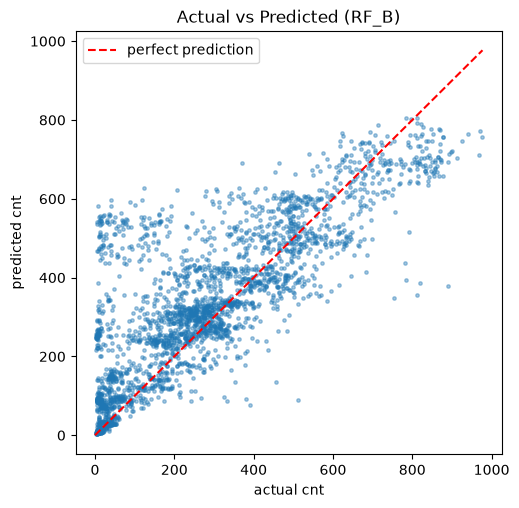

In [20]:
plt.figure(figsize=(5.5, 5.5))
plt.scatter(valid_res["cnt"], valid_res["pred"], s=6, alpha=0.4)
lim = max(valid_res["cnt"].max(), valid_res["pred"].max())
plt.plot([0, lim], [0, lim], "r--", label="perfect prediction")
plt.xlabel("actual cnt")
plt.ylabel("predicted cnt")
plt.title(f"Actual vs Predicted ({candidate_name})")
plt.legend()
plt.show()

**읽는 법**: 점이 빨간 점선(완벽한 예측)에 가까울수록 좋습니다. 대여량이 큰 쪽에서 점이 점선 아래로 처지면 많이 빌려지는 시간대를 실제보다 적게 예측한다는 뜻입니다.

### 시간대별 MAE

,MAE
hr,
0,99.0
1,118.8
2,118.0
3,170.5
4,114.9
5,119.3
6,105.2
7,117.1
8,123.5


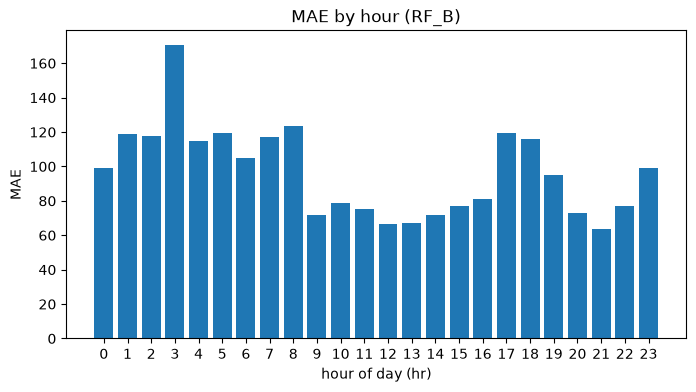

MAE가 큰 시간대 상위 5개: {3: 170.5, 8: 123.5, 17: 119.7, 5: 119.3, 1: 118.8}


In [21]:
hour_mae = valid_res.groupby("hr")["abs_err"].mean()
display(hour_mae.round(1).to_frame("MAE"))

plt.figure(figsize=(8, 4))
plt.bar(hour_mae.index, hour_mae.values)
plt.xticks(range(0, 24))
plt.xlabel("hour of day (hr)")
plt.ylabel("MAE")
plt.title(f"MAE by hour ({candidate_name})")
plt.show()

print("MAE가 큰 시간대 상위 5개:", hour_mae.sort_values(ascending=False).head(5).round(1).to_dict())

### ✏️ 내 메모 (CP-07) — 직접 판단해서 채우세요
- 오류가 큰 시간대는 언제인가요? 그 시간대의 대여 패턴과 연결해 보면?
- 모델이 전반적으로 많이/적게 예측하는 경향이 있나요? (평균 잔차, 산점도)
- **최종 모델 결정**: Validation MAE, Train·Validation 격차, 시간대별 오류, 장단점을 함께 고려해 아래에 결정과 근거를 적으세요.

(여기에 적기)

아래 셀에서 최종 모델 이름을 지정합니다. 기본값은 Validation MAE 1등이지만, **Train·Validation 격차까지 보고 다른 모델이 낫다고 판단하면 직접 바꾸세요.** (예: `"RF_A"`)

> ⚠️ 이 선택은 **Validation 결과만** 보고 합니다. Test 결과를 본 뒤에 바꾸면 안 됩니다.

In [22]:
SELECTED_MODEL_NAME = candidate_name   # 필요하면 직접 바꾸기. 예: "RF_A"
print("최종 선택 모델:", SELECTED_MODEL_NAME)

최종 선택 모델: RF_B


---
# ⑧ CP-08 · 최종 모델 완성 및 예측

### 1~2단계. Train + Validation으로 재학습하고 Test로 평가
모델과 설정을 확정했으니, Validation 데이터도 학습에 합쳐서 **더 많은 데이터로 다시 학습**합니다. 그리고 지금까지 한 번도 쓰지 않은 **Test**로 최종 성능을 **딱 한 번** 확인합니다.

> ⚠️ Test 결과를 본 뒤 모델이나 설정을 다시 고르지 않습니다.

In [23]:
X_trval = pd.concat([X_train, X_valid])
y_trval = pd.concat([y_train, y_valid])

final_model = Pipeline([("pre", make_preprocessor()),
                        ("model", MODEL_FACTORIES[SELECTED_MODEL_NAME]())])
final_model.fit(X_trval, y_trval)

test_pred = final_model.predict(X_test)
test_scores = evaluate_regression(y_test, test_pred)
print(f"[{SELECTED_MODEL_NAME}] Test 성능:", {k: round(float(v), 3) for k, v in test_scores.items()})

[RF_B] Test 성능: {'MAE': 66.17, 'RMSE': 95.878, 'R2': 0.8}


### 3~4단계. 모델 저장 · 불러오기
`joblib.dump()`로 **전처리 + 모델이 묶인 Pipeline**을 파일로 저장합니다. 저장한 파일을 다시 `joblib.load()`로 불러와서, 원래 모델과 예측이 같은지 확인합니다.

In [24]:
os.makedirs("../results", exist_ok=True)

MODEL_PATH = "../results/01_final_regressor.joblib"
joblib.dump(final_model, MODEL_PATH, compress=3)   # compress: 파일 용량 줄이기
print("저장 완료:", MODEL_PATH)

loaded_model = joblib.load(MODEL_PATH)
same = np.allclose(loaded_model.predict(X_test), final_model.predict(X_test))
print("불러온 모델의 예측이 원래 모델과 같은가:", same)

# 비교표도 결과 폴더에 저장
results_df.round(4).to_csv("../results/01_model_comparison.csv")
print("모델 비교표 저장 완료: ../results/01_model_comparison.csv")

저장 완료: ../results/01_final_regressor.joblib
불러온 모델의 예측이 원래 모델과 같은가: True
모델 비교표 저장 완료: ../results/01_model_comparison.csv


### 5단계. 예측 함수 `predict_demand()`
입력값을 받아 예상 대여량을 돌려줍니다. 학습할 때 쓴 `is_commute_hour`를 **예측할 때도 똑같이 만들어야** 하므로 `add_commute_feature()`를 그대로 사용합니다.

입력값 규칙(UCI 데이터 기준): `season` 1봄·2여름·3가을·4겨울 / `yr` 0=2011, 1=2012 / `weekday` 0=일요일~6=토요일 / `weathersit` 1맑음~4악천후 / `temp`·`atemp`·`hum`·`windspeed`는 **0~1 사이 정규화 값**

In [25]:
def predict_demand(season, yr, mnth, hr, weekday, holiday, workingday,
                   weathersit, temp, atemp, hum, windspeed, model=None):
    """입력 한 건에 대한 예상 시간당 대여량(대)을 반환한다."""
    model = model if model is not None else loaded_model
    row = pd.DataFrame([{
        "season": season, "yr": yr, "mnth": mnth, "hr": hr, "weekday": weekday,
        "holiday": holiday, "workingday": workingday, "weathersit": weathersit,
        "temp": temp, "atemp": atemp, "hum": hum, "windspeed": windspeed,
    }])
    row = add_commute_feature(row)               # 학습 때와 같은 방식으로 특성 생성
    return float(model.predict(row[FEATURES])[0])

# 예시 1: 가을(3), 2012년, 9월, 평일(수요일) 오전 8시, 맑음, 따뜻한 날씨
print("평일 출근 시간 예상 대여량:", round(predict_demand(3, 1, 9, 8, 3, 0, 1, 1, 0.6, 0.58, 0.5, 0.2), 1))
# 예시 2: 같은 날 새벽 3시
print("평일 새벽 3시 예상 대여량  :", round(predict_demand(3, 1, 9, 3, 3, 0, 1, 1, 0.5, 0.48, 0.6, 0.1), 1))

평일 출근 시간 예상 대여량: 727.7
평일 새벽 3시 예상 대여량  : 9.6


### ✏️ 최종 점검 질문 (직접 답해 보세요)
1. 어떤 정보를 사용해 대여량을 예측했고, 사용하지 않은 정보는 왜 제외했나요?
2. 어떤 모델을 실험했고, 검증 성능에 어떤 차이가 있었나요?
3. 최종 모델을 고른 근거는? 이 모델이 잘 못 맞히는 상황은?

(여기에 적기)